# MLP на табличных данных: SUPPORT2 — функциональный исход тяжелобольных пациентов

**Задача:** по данным на 3-й день госпитализации предсказать функциональное состояние пациента через 2 месяца
(мультиклассовая классификация, 4 класса).

Весь переиспользуемый код вынесен в пакет `mlp_lab/` (модели, обучение, эксперименты, градиенты, активации, графики).
Специфика датасета собрана в `mlp_lab/data.py`. Ноутбук только вызывает пакет и интерпретирует результаты.

## 0. Конфигурация

In [1]:
import platform
from dataclasses import asdict, replace
from pathlib import Path

import numpy as np
import pandas as pd
import torch
from IPython.display import display
from sklearn.metrics import classification_report

from mlp_lab import ModelConfig, TrainConfig, count_parameters, resolve_device, set_seed
from mlp_lab import activations, data as support2, plots
from mlp_lab.experiments import run_depth_width_grid, summarize_grid, train_model
from mlp_lab.gradients import GradientExtractor

plots.set_style()
pd.set_option("display.max_columns", 60)
pd.set_option("display.float_format", "{:.4f}".format)
print(f"python {platform.python_version()} | torch {torch.__version__} | numpy {np.__version__} | pandas {pd.__version__}")

python 3.14.9 | torch 2.15.0 | numpy 2.5.3 | pandas 3.0.6


In [2]:
# ---- Конфигурация эксперимента ----
DATA_PATH = Path("data/raw/support2.csv")
RESULTS_DIR = Path("results")
SEED = 42
DEVICE = "cpu"
SPLIT = dict(valid_size=0.15, test_size=0.15)

BASELINE_HIDDEN = [128, 64]
BASELINE_DROPOUT = 0.2
TRAIN = TrainConfig(lr=1e-3, weight_decay=1e-4, batch_size=128, max_epochs=300, patience=25,
                    use_class_weights=True, device=DEVICE, seed=SEED)

# Демонстрация переобучения: большая сеть, фиксированное число эпох без early stopping.
OVERFIT_HIDDEN = [512, 512, 512]
OVERFIT_EPOCHS = 200
REGULARIZED = dict(dropout=0.7, weight_decay=0.5)

# Сетка глубина × ширина.
GRID_DEPTHS = [1, 2, 3, 4, 6, 8]
GRID_WIDTHS = [16, 32, 64, 128, 256, 512]
GRID_SEEDS = [0, 1, 2]
GRID_CACHE = RESULTS_DIR / "depth_width_grid.csv"
RERUN_GRID = False         # True — пересчитать сетку, даже если CSV уже есть

# Градиенты: глубокая сеть для сравнения с базовой.
DEEP_HIDDEN = [64] * 8

RESULTS_DIR.mkdir(parents=True, exist_ok=True)
set_seed(SEED)
print("device:", resolve_device(DEVICE))

device: cpu


## 1. Датасет

**SUPPORT2** — *Study to Understand Prognoses and Preferences for Outcomes and Risks of Treatments*
([UCI ML Repository, id 880](https://archive.ics.uci.edu/dataset/880/support2)). Клиническое исследование 9105 тяжелобольных
взрослых пациентов в пяти американских медицинских центрах (1989–1994).

In [3]:
support2.download_support2(DATA_PATH)
raw = support2.load_raw(DATA_PATH)
print("объектов × колонок:", raw.shape)
raw.head()

объектов × колонок: (9105, 48)


,id,age,death,sex,hospdead,slos,d.time,dzgroup,dzclass,num.co,edu,income,scoma,charges,totcst,totmcst,avtisst,race,sps,aps,surv2m,surv6m,hday,diabetes,dementia,ca,prg2m,prg6m,dnr,dnrday,meanbp,wblc,hrt,resp,temp,pafi,alb,bili,crea,sod,ph,glucose,bun,urine,adlp,adls,sfdm2,adlsc
0,1,62.8500,0,male,0,5,2029,Lung Cancer,Cancer,0,11.0000,$11-$25k,0.0000,9715.0000,NaN,NaN,7.0000,other,33.8984,20.0000,0.2629,0.0370,1,0,0,metastatic,0.5000,0.2500,no dnr,5.0000,97.0000,6.0000,69.0000,22.0000,36.0000,388.0000,1.7998,0.2000,1.2000,141.0000,7.4600,NaN,NaN,NaN,7.0000,7.0000,NaN,7.0000
1,2,60.3390,1,female,1,4,4,Cirrhosis,COPD/CHF/Cirrhosis,2,12.0000,$11-$25k,44.0000,34496.0000,NaN,NaN,29.0000,white,52.6953,74.0000,0.0010,0.0000,3,0,0,no,0.0000,0.0000,NaN,NaN,43.0000,17.0977,112.0000,34.0000,34.5938,98.0000,NaN,NaN,5.5000,132.0000,7.2500,NaN,NaN,NaN,NaN,1.0000,<2 mo. follow-up,1.0000
2,3,52.7470,1,female,0,17,47,Cirrhosis,COPD/CHF/Cirrhosis,2,12.0000,under $11k,0.0000,41094.0000,NaN,NaN,13.0000,white,20.5000,45.0000,0.7909,0.6649,4,0,0,no,0.7500,0.5000,no dnr,17.0000,70.0000,8.5000,88.0000,28.0000,37.3984,231.6562,NaN,2.1997,2.0000,134.0000,7.4600,NaN,NaN,NaN,1.0000,0.0000,<2 mo. follow-up,0.0000
3,4,42.3850,1,female,0,3,133,Lung Cancer,Cancer,2,11.0000,under $11k,0.0000,3075.0000,NaN,NaN,7.0000,white,20.0977,19.0000,0.6990,0.4120,1,0,0,metastatic,0.9000,0.5000,no dnr,3.0000,75.0000,9.0996,88.0000,32.0000,35.0000,NaN,NaN,NaN,0.7999,139.0000,NaN,NaN,NaN,NaN,0.0000,0.0000,no(M2 and SIP pres),0.0000
4,5,79.8850,0,female,0,16,2029,ARF/MOSF w/Sepsis,ARF/MOSF,1,NaN,NaN,26.0000,50127.0000,NaN,NaN,18.6667,white,23.5000,30.0000,0.6349,0.5330,3,0,0,no,0.9000,0.9000,no dnr,16.0000,59.0000,13.5000,112.0000,20.0000,37.8984,173.3125,NaN,NaN,0.7999,143.0000,7.5098,NaN,NaN,NaN,NaN,2.0000,no(M2 and SIP pres),2.0000


In [4]:
raw[support2.TARGET].value_counts(dropna=False).to_frame("count")

,count
sfdm2,
<2 mo. follow-up,3123
no(M2 and SIP pres),3061
NaN,1400
adl>=4 (>=5 if sur),916
SIP>=30,564
Coma or Intub,41


## 2. Первичный анализ данных

Анализируем строки с известным таргетом. Признаки берём **до** кодирования и заполнения пропусков, чтобы видеть данные как есть.
Колонки, которые позже выбрасываются из-за утечки, сюда не входят — их смысл разобран в разделе 3.

In [5]:
eda = raw.dropna(subset=[support2.TARGET]).copy()
eda["target"] = eda[support2.TARGET].map(support2.TARGET_MAP).map({c: i for i, c in enumerate(support2.CLASS_NAMES)})
feature_cols = support2.NUMERIC_COLS + support2.BINARY_COLS + support2.CATEGORICAL_COLS
print("объектов с таргетом:", len(eda), "| признаков:", len(feature_cols))
print("типы:", {"числовые": len(support2.NUMERIC_COLS), "бинарные": len(support2.BINARY_COLS), "категориальные": len(support2.CATEGORICAL_COLS)})
eda[support2.NUMERIC_COLS].describe().T

объектов с таргетом: 7705 | признаков: 29
типы: {'числовые': 22, 'бинарные': 2, 'категориальные': 5}


,count,mean,std,min,25%,50%,75%,max
age,7705.0000,62.9128,15.5911,18.1190,53.0320,65.0460,74.3270,100.8490
num.co,7705.0000,1.8793,1.3511,0.0000,1.0000,2.0000,3.0000,9.0000
edu,6660.0000,11.7117,3.4374,0.0000,10.0000,12.0000,14.0000,31.0000
scoma,7704.0000,13.0541,25.7883,0.0000,0.0000,0.0000,9.0000,100.0000
sps,7704.0000,26.0865,10.1580,0.2000,19.3984,24.3984,30.7969,99.1875
aps,7704.0000,38.7360,20.3208,0.0000,24.0000,35.0000,50.0000,143.0000
hday,7705.0000,4.5552,9.2976,1.0000,1.0000,1.0000,4.0000,148.0000
adlsc,7705.0000,1.8477,2.0499,0.0000,0.0000,1.0000,3.0000,7.0732
meanbp,7704.0000,84.2671,28.0135,0.0000,63.0000,77.0000,107.0000,195.0000
hrt,7704.0000,97.3996,31.8250,0.0000,72.0000,100.0000,120.0000,300.0000


In [6]:
eda[support2.CATEGORICAL_COLS].describe().T

,count,unique,top,freq
sex,7705,2,male,4331
race,7676,5,white,6094
dzgroup,7705,8,ARF/MOSF w/Sepsis,3015
income,5494,4,under $11k,2571
ca,7705,3,no,5090


### 2.1 Баланс классов

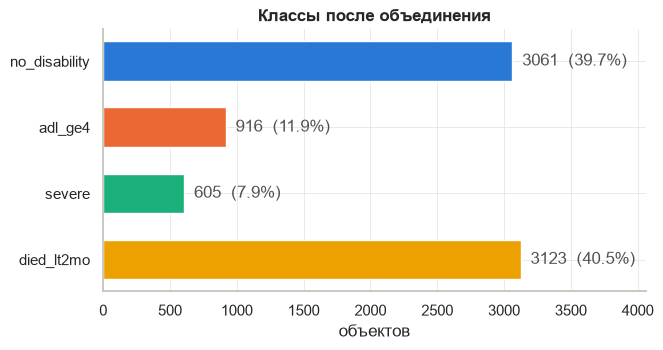

In [7]:
plots.plot_class_distribution(eda["target"], support2.CLASS_NAMES, title="Классы после объединения");

**Вывод.** Классы несбалансированы: `died_lt2mo` ≈ 40.5%, `no_disability` ≈ 39.7%, `adl_ge4` ≈ 11.9%, `severe` ≈ 7.9% (отношение крупного к мелкому ≈ 5 : 1). Константный классификатор дал бы accuracy ≈ 40%, поэтому accuracy здесь мало что говорит. Отсюда три решения: главная метрика — **macro-F1**, loss взвешивается по классам, разбиение стратифицированное.

### 2.2 Пропуски

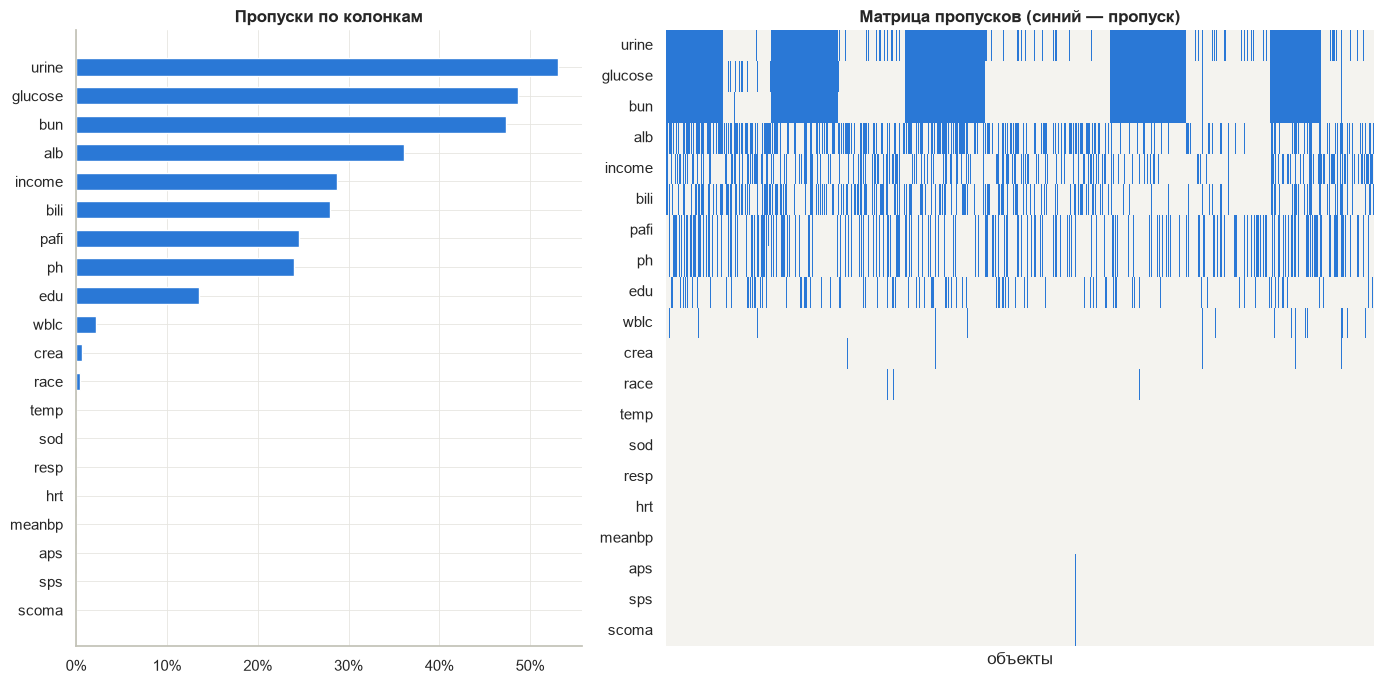

In [8]:
plots.plot_missing(eda[feature_cols]);

**Вывод.** Пропуски сосредоточены в лабораторных анализах (`urine` 53%, `glucose` 49%, `bun` 47%, `alb` 36%, `bili` 28%, `pafi`/`ph` ≈ 24%) и в социальных признаках (`income` 29%, `edu` 14%). На матрице видны **сплошные блоки**: `urine`, `glucose`, `bun` пропущены одновременно у длинных серий подряд идущих пациентов. Похоже, на части этапов или в части центров эти анализы просто не собирали. Значит, пропуски **не случайны**, и сам факт пропуска несёт информацию. Поэтому к заполнению добавлены флаги `*_missing`. Физиологические показатели (`sps`, `aps`, `meanbp`, `hrt`, `resp`, `temp`, `sod`) почти полные.

### 2.3 Распределения числовых признаков по классам

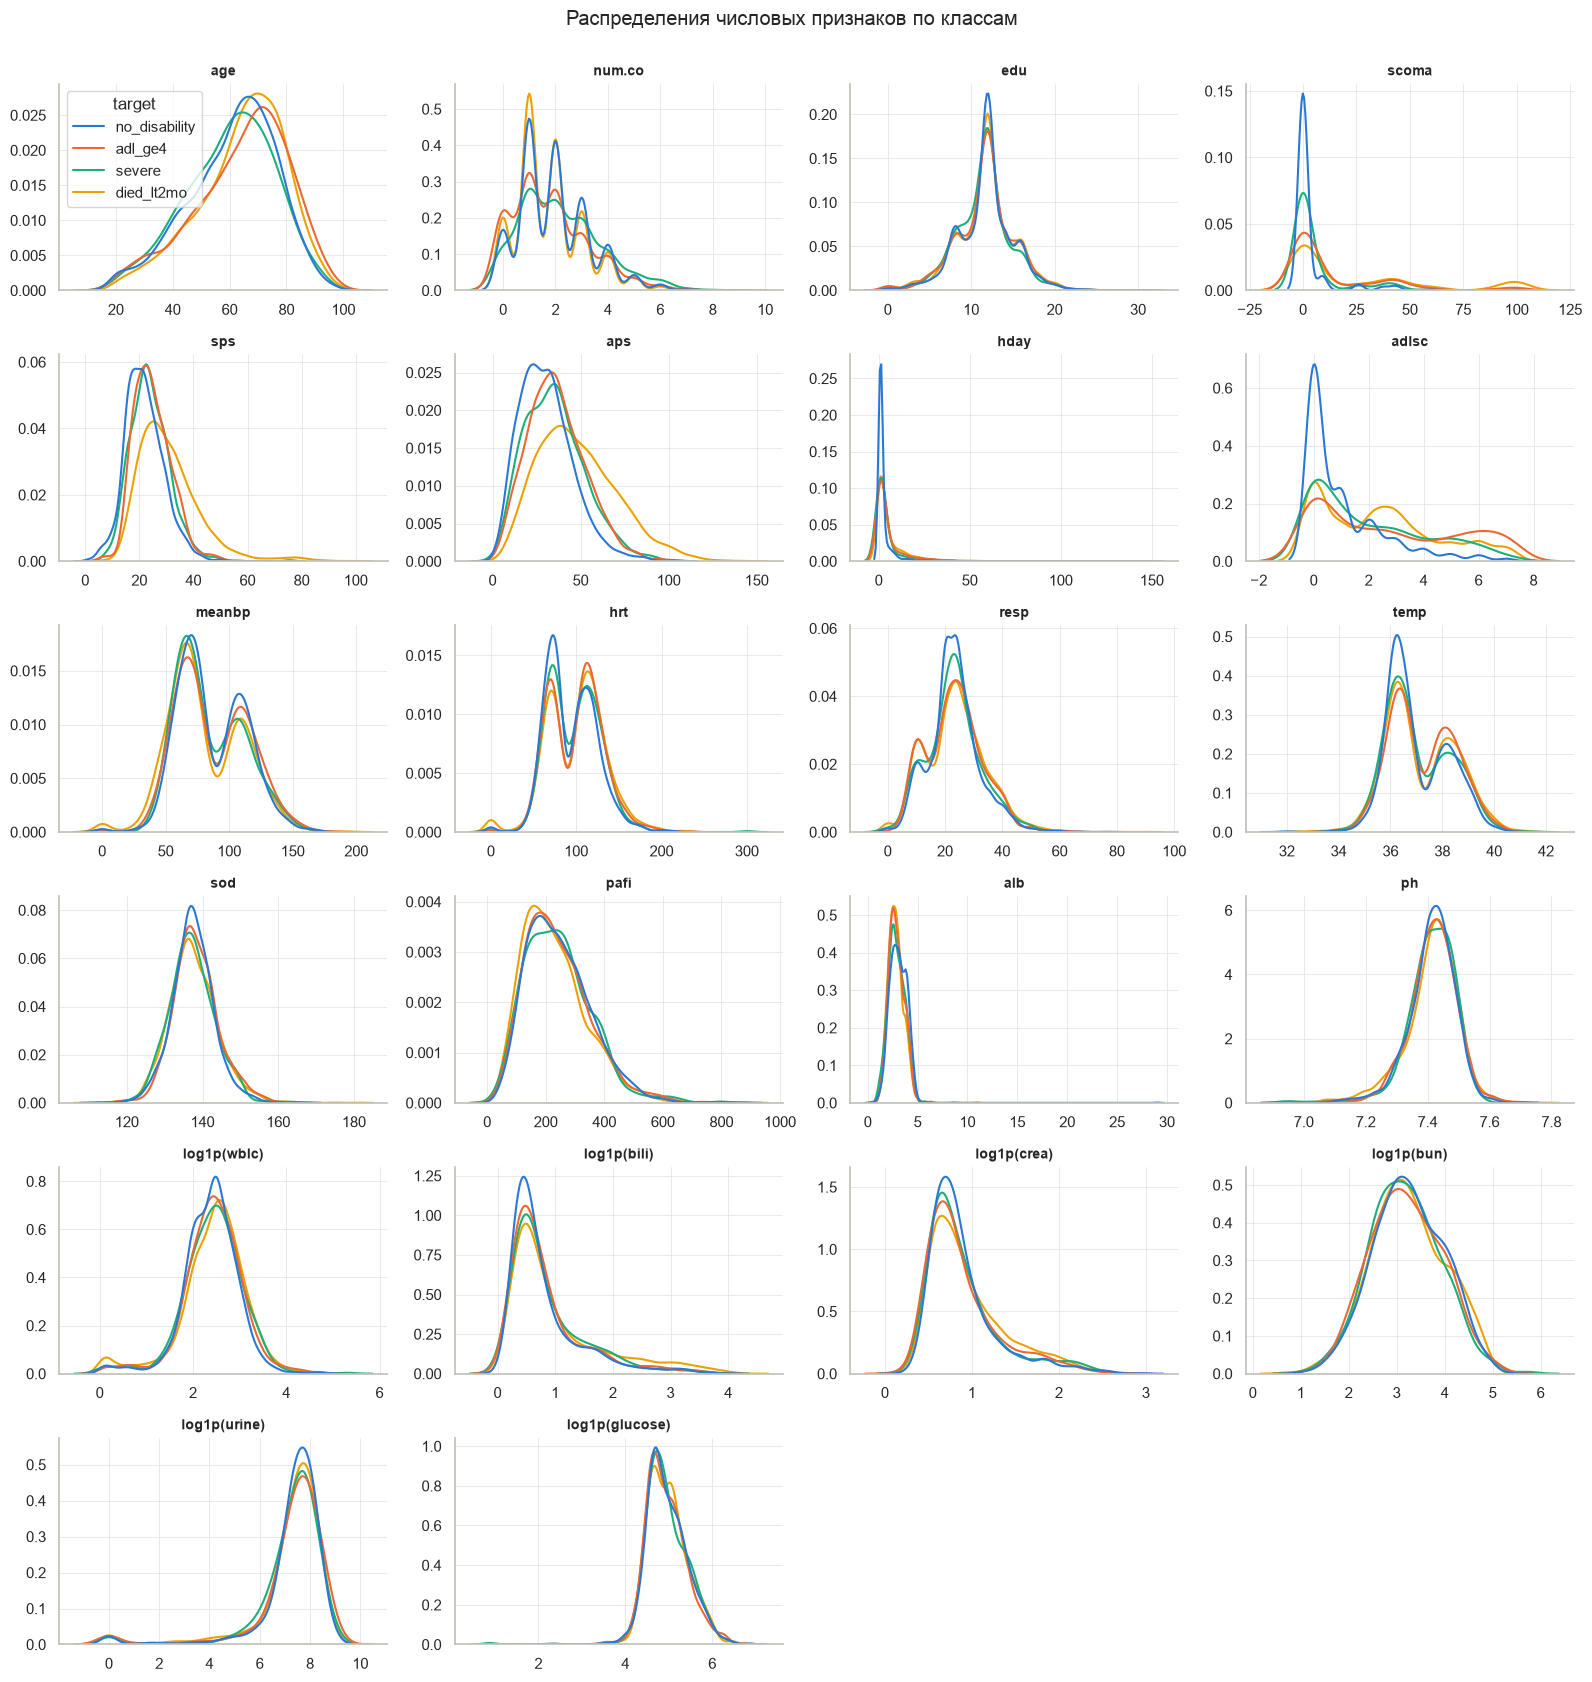

In [9]:
plots.plot_numeric_by_class(eda, support2.NUMERIC_COLS, "target", support2.CLASS_NAMES, log_cols=support2.LOG_COLS);

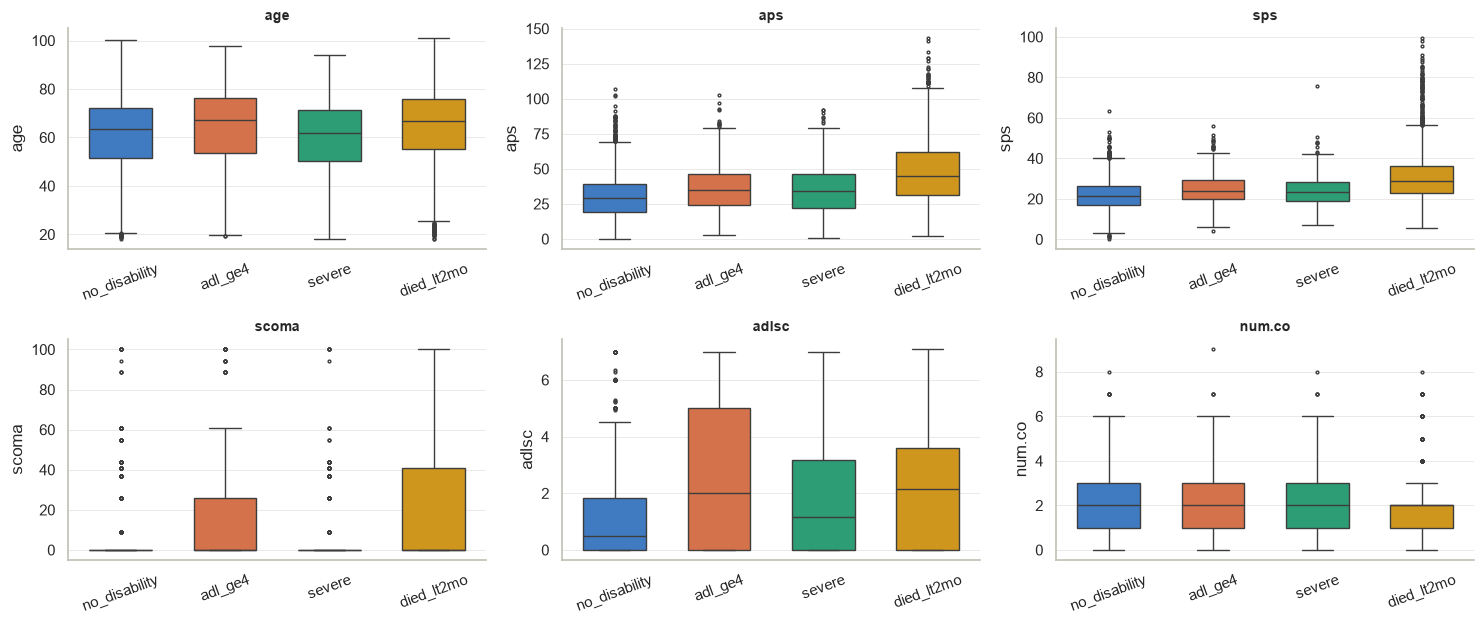

In [10]:
plots.plot_box_by_class(eda, ["age", "aps", "sps", "scoma", "adlsc", "num.co"], "target", support2.CLASS_NAMES);

**Вывод.**
* Лучше всего классы разделяют **интегральные шкалы тяжести** `sps` и `aps`: у `died_lt2mo` распределение заметно сдвинуто вправо. Также информативны `scoma` (у `no_disability` почти вся масса в 0, у умерших есть хвост до 100) и `adlsc`: у `no_disability` пик в 0, у `adl_ge4` заметная масса при 5–7. Исходные нарушения бытовой активности предсказывают инвалидизацию.
* Возраст сдвигает классы слабо: умершие и `adl_ge4` немного старше.
* У большинства анализов (`temp`, `sod`, `ph`, `pafi`, `bun`, `glucose`) распределения по классам почти совпадают, по отдельности они слабые. Ожидаемое качество модели умеренное.
* `bili`, `crea`, `urine`, `wblc`, `glucose`, `bun` сильно скошены вправо, `hday` имеет тяжёлый хвост. Отсюда `log1p` перед стандартизацией. После него распределения близки к колоколу.
* Промежуточные классы `adl_ge4` и `severe` по большинству признаков лежат между `no_disability` и `died_lt2mo` и сильно перекрываются с ними. Именно на них стоит ждать ошибок.

### 2.4 Категориальные признаки и таргет

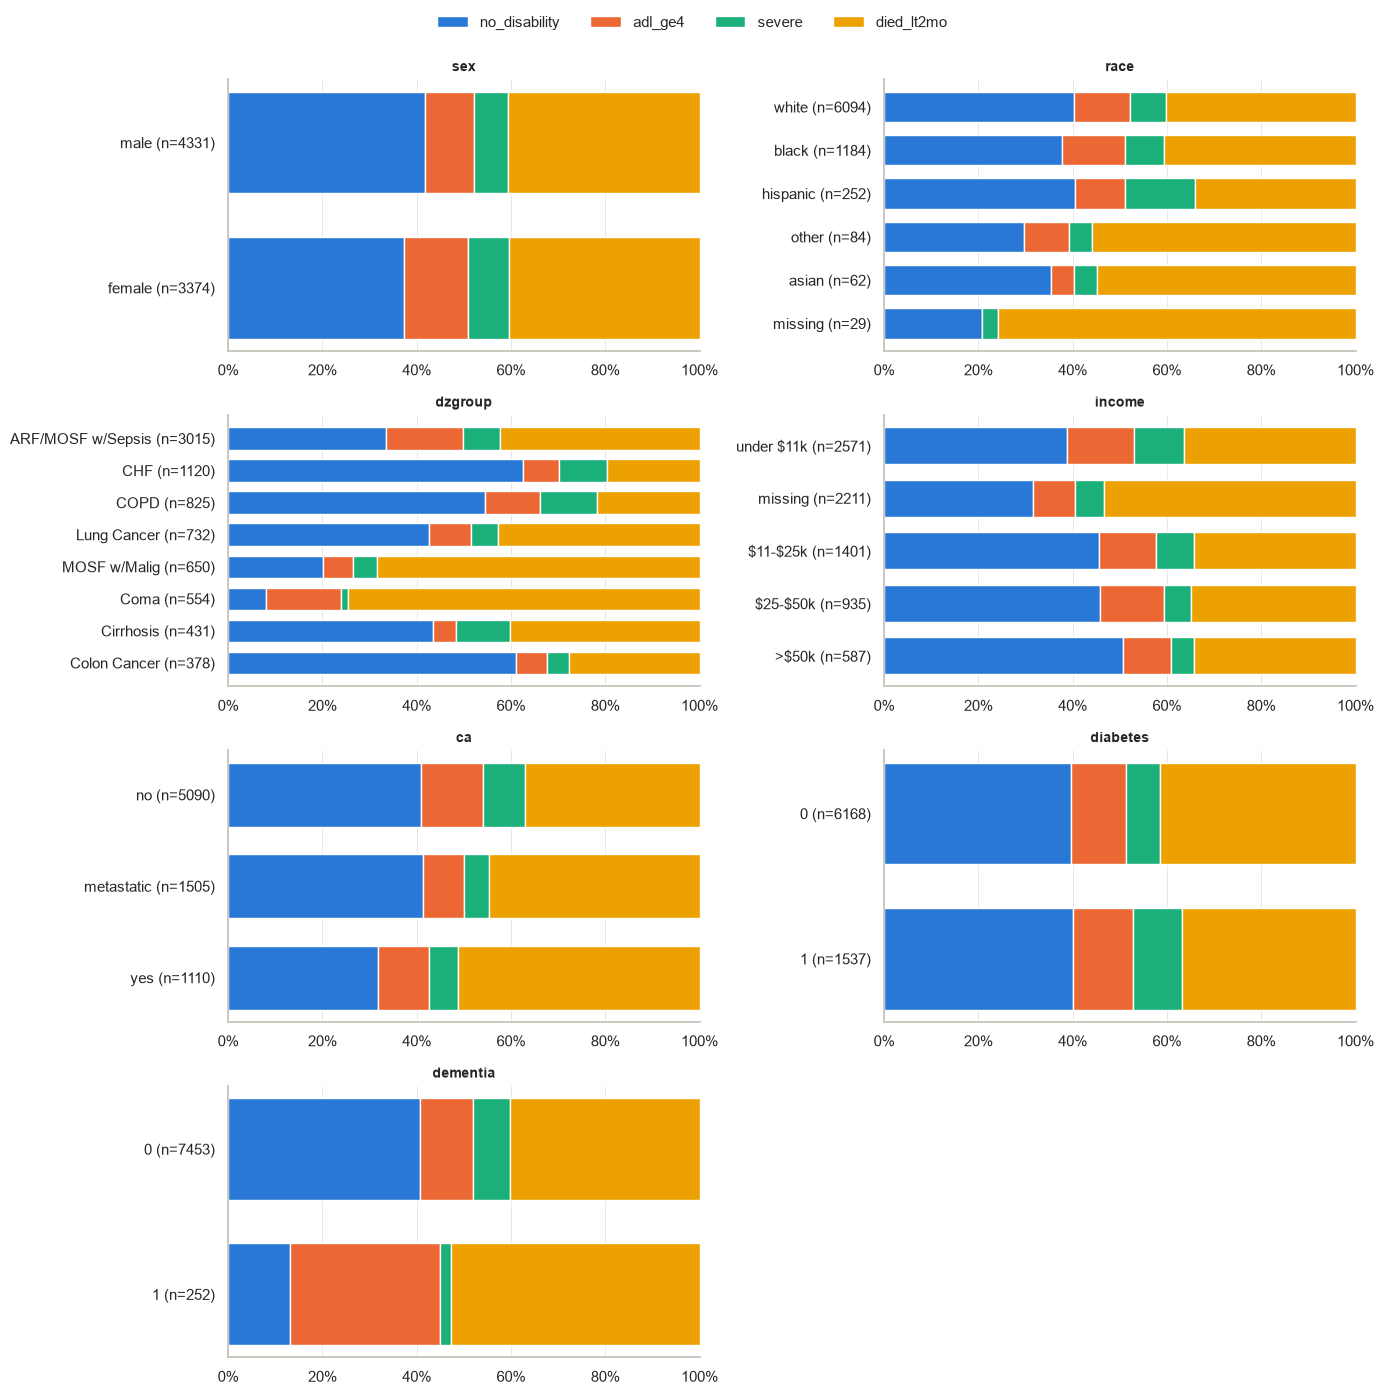

In [11]:
plots.plot_categorical_vs_target(eda, support2.CATEGORICAL_COLS + ["diabetes", "dementia"], "target", support2.CLASS_NAMES);

**Вывод.**
* `dzgroup` — самый информативный категориальный признак: при `Coma` ≈ 75% пациентов умирают в течение 2 месяцев, при `MOSF w/Malig` ≈ 68%, а при `CHF` и `Colon Cancer` ≈ 60% остаются без инвалидизации.
* `dementia = 1` резко меняет картину: без инвалидизации остаются только ≈ 13%, а доля `adl_ge4` вырастает до ≈ 32%.
* У пациентов с пропуском `income` (и `race`) доля умерших выше, чем у остальных. Это ещё одно подтверждение, что пропуск информативен, и аргумент за отдельную категорию `missing`.
* `sex` и `diabetes` почти не меняют состав классов.

### 2.5 Корреляции

Используем корреляцию Спирмена: она устойчива к выбросам и скошенности и улавливает монотонные нелинейные связи.
Таргет порядковый, поэтому его код (0 — нет инвалидизации … 3 — смерть) тоже можно включить в матрицу.

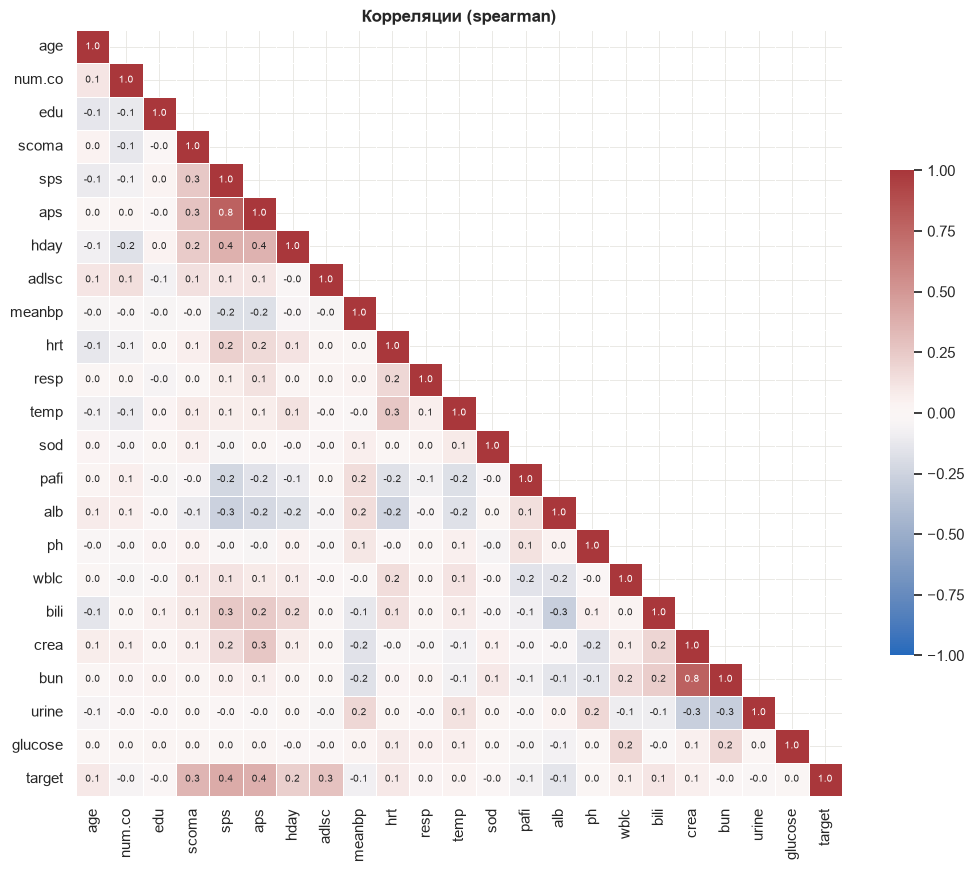

In [12]:
plots.plot_correlation(eda, support2.NUMERIC_COLS + ["target"], method="spearman");

In [13]:
eda[support2.NUMERIC_COLS].corrwith(eda["target"], method="spearman").sort_values(key=abs, ascending=False).to_frame("spearman с таргетом").head(10)

,spearman с таргетом
sps,0.4027
aps,0.3758
scoma,0.3456
adlsc,0.2832
hday,0.2256
alb,-0.1457
bili,0.1112
age,0.0970
hrt,0.0969
meanbp,-0.0808


**Вывод.**
* С таргетом сильнее всего связаны `sps` (ρ ≈ 0.40), `aps` (0.38), `scoma` (0.35), `adlsc` (0.28), `hday` (0.23). У остальных |ρ| < 0.15. Линейная связь каждого признака с исходом слабая, качество будет зависеть от комбинаций признаков, и это аргумент за нелинейную модель.
* Заметная мультиколлинеарность: `sps` ↔ `aps` (ρ ≈ 0.8, обе шкалы считаются из одной физиологии) и `crea` ↔ `bun` (0.8, оба маркеры функции почек). MLP с регуляризацией к этому устойчив, поэтому признаки оставлены.
* Почти все остальные пары почти не коррелируют: признаки несут разную информацию.

## 3. Предобработка и разбиение данных

### 3.1 Какие колонки выбрасываем и почему

| группа | колонки | причина |
|---|---|---|
| **утечка таргета** | `death`, `hospdead`, `d.time`, `slos`, `charges`, `totcst`, `totmcst`, `avtisst`, `dnr`, `dnrday` | известны только после 3-го дня: факт смерти, длительность и стоимость лечения, поздние решения. На момент прогноза их нет, а модель с ними «подсмотрит ответ» |
| **чужие прогнозы** | `surv2m`, `surv6m`, `prg2m`, `prg6m` | выход прогнозной модели SUPPORT и оценка врача: сеть научилась бы копировать чужое предсказание |
| **дубли** | `id`, `dzclass`, `adlp`, `adls` | идентификатор; `dzclass` — огрубление `dzgroup`; `adlp`/`adls` сведены авторами в `adlsc` без пропусков |

### 3.2 Пропуски и кодирование

* **Анализы** (`alb`, `pafi`, `bili`, `crea`, `bun`, `wblc`, `urine`) заполняются «нормальными» значениями, которые рекомендуют
  авторы SUPPORT: анализ чаще не делают, когда врач считает показатель нормальным. Для `ph`, `glucose` рекомендаций нет —
  заполняются медианой. Для всех этих анализов добавляется бинарный флаг `*_missing`: сам факт отсутствия анализа информативен.
* Остальные числовые → медиана; скошенные (`wblc`, `bili`, `crea`, `bun`, `urine`, `glucose`) → `log1p`; все числовые → `StandardScaler`.
* Категориальные → отдельная категория `missing` → one-hot (кардинальность ≤ 8, embedding не нужен).
* **Медианы, параметры масштабирования и словари one-hot считаются только по train**, иначе информация из valid/test
  просочится в обучение. Константы из литературы от данных не зависят, поэтому их можно подставить до разбиения.

In [14]:
X, y = support2.prepare_frame(raw)
print("X:", X.shape, "| y:", y.shape)
X.head()

X: (7705, 38) | y: (7705,)


,age,num.co,edu,scoma,sps,aps,hday,adlsc,meanbp,hrt,resp,temp,sod,pafi,alb,ph,wblc,bili,crea,bun,urine,glucose,diabetes,dementia,alb_missing,pafi_missing,bili_missing,crea_missing,bun_missing,wblc_missing,urine_missing,ph_missing,glucose_missing,sex,race,dzgroup,income,ca
0,60.3390,2,12.0000,44.0000,52.6953,74.0000,3,1.0000,43.0000,112.0000,34.0000,34.5938,132.0000,98.0000,3.5000,7.2500,17.0977,1.0100,5.5000,6.5100,2502.0000,NaN,0,0,1,0,1,0,1,0,1,0,1,female,white,Cirrhosis,$11-$25k,no
1,52.7470,2,12.0000,0.0000,20.5000,45.0000,4,0.0000,70.0000,88.0000,28.0000,37.3984,134.0000,231.6562,3.5000,7.4600,8.5000,2.1997,2.0000,6.5100,2502.0000,NaN,0,0,1,0,0,0,1,0,1,0,1,female,white,Cirrhosis,under $11k,no
2,42.3850,2,11.0000,0.0000,20.0977,19.0000,1,0.0000,75.0000,88.0000,32.0000,35.0000,139.0000,333.3000,3.5000,NaN,9.0996,1.0100,0.7999,6.5100,2502.0000,NaN,0,0,1,1,1,0,1,0,1,1,1,female,white,Lung Cancer,under $11k,metastatic
3,79.8850,1,NaN,26.0000,23.5000,30.0000,3,2.0000,59.0000,112.0000,20.0000,37.8984,143.0000,173.3125,3.5000,7.5098,13.5000,1.0100,0.7999,6.5100,2502.0000,NaN,0,0,1,0,1,0,1,0,1,0,1,female,white,ARF/MOSF w/Sepsis,NaN,no
4,93.0160,1,14.0000,55.0000,19.3984,27.0000,1,1.0000,110.0000,101.0000,44.0000,38.3984,140.0000,266.6250,3.5000,7.6592,10.3984,1.0100,0.7000,6.5100,2502.0000,NaN,0,0,1,0,1,0,1,0,1,0,1,male,white,Coma,NaN,no


### 3.3 Разбиение train / valid / test = 70 / 15 / 15

* **train** — подбор весов сети и параметров препроцессинга;
* **valid** — всё, что выбирается *по данным, но не градиентом*: момент остановки (early stopping), архитектура в п.5,
  сравнение регуляризаций. Из-за многократных проверок оценка на valid становится оптимистичной: мы под неё подстраиваемся;
* **test** — откладывается и используется **один раз** в конце, чтобы получить честную оценку обобщающей способности.

Разбиение **стратифицированное**: доли классов во всех трёх выборках одинаковые. Без этого редкий класс `severe`
(≈ 8%) мог бы случайно почти пропасть из valid или test, и метрики по нему стали бы шумом.

In [15]:
splits = support2.train_valid_test_split(X, y, seed=SEED, **SPLIT)
pd.DataFrame(
    {name: ys.value_counts(normalize=True).sort_index().rename(dict(enumerate(support2.CLASS_NAMES))) for name, (_, ys) in splits.items()}
).T.assign(n=[len(ys) for _, ys in splits.values()])

target,no_disability,adl_ge4,severe,died_lt2mo,n
train,0.3974,0.1189,0.0784,0.4053,5393
valid,0.3971,0.1194,0.0787,0.4048,1156
test,0.3971,0.1185,0.0787,0.4057,1156


In [16]:
data, feature_names = support2.transform_splits(splits, support2.build_preprocessor())
for name, (Xs, ys) in data.items():
    print(f"{name:5s} X={Xs.shape}  y={ys.shape}")
print("признаков после кодирования:", len(feature_names))
print(feature_names)

train X=(5393, 57)  y=(5393,)
valid X=(1156, 57)  y=(1156,)
test  X=(1156, 57)  y=(1156,)
признаков после кодирования: 57
['wblc', 'bili', 'crea', 'bun', 'urine', 'glucose', 'age', 'num.co', 'edu', 'scoma', 'sps', 'aps', 'hday', 'adlsc', 'meanbp', 'hrt', 'resp', 'temp', 'sod', 'pafi', 'alb', 'ph', 'diabetes', 'dementia', 'alb_missing', 'pafi_missing', 'bili_missing', 'crea_missing', 'bun_missing', 'wblc_missing', 'urine_missing', 'ph_missing', 'glucose_missing', 'sex_female', 'sex_male', 'race_asian', 'race_black', 'race_hispanic', 'race_missing', 'race_other', 'race_white', 'dzgroup_ARF/MOSF w/Sepsis', 'dzgroup_CHF', 'dzgroup_COPD', 'dzgroup_Cirrhosis', 'dzgroup_Colon Cancer', 'dzgroup_Coma', 'dzgroup_Lung Cancer', 'dzgroup_MOSF w/Malig', 'income_$11-$25k', 'income_$25-$50k', 'income_>$50k', 'income_missing', 'income_under $11k', 'ca_metastatic', 'ca_no', 'ca_yes']


In [17]:
X_tr = pd.DataFrame(data["train"][0], columns=feature_names)
X_te = pd.DataFrame(data["test"][0], columns=feature_names)
num_names = support2.LOG_COLS + [c for c in support2.NUMERIC_COLS if c not in support2.LOG_COLS]
pd.DataFrame({"train mean": X_tr[num_names].mean(), "train std": X_tr[num_names].std(),
              "test mean": X_te[num_names].mean(), "test std": X_te[num_names].std()}).head(8)

,train mean,train std,test mean,test std
wblc,0.0000,1.0001,0.0138,1.0268
bili,-0.0000,1.0001,-0.0374,0.9648
crea,-0.0000,1.0001,0.0098,0.9711
bun,-0.0000,1.0001,0.0718,1.0486
urine,-0.0000,1.0001,-0.0485,1.1174
glucose,-0.0000,1.0001,0.0191,1.0318
age,-0.0000,1.0001,-0.0087,0.9918
num.co,0.0000,1.0001,0.0034,0.9661


Числовые признаки на train имеют среднее 0 и std 1, на test — близко к этому, но не точно: скейлер обучен только на train.

## 4. Базовый MLP

**Архитектура:** `Linear(57→128) → ReLU → Dropout(0.2) → Linear(128→64) → ReLU → Dropout(0.2) → Linear(64→4)`.

**Обучение:** AdamW (lr = 1e-3, weight_decay = 1e-4), батч 128, `CrossEntropyLoss` с весами классов, обратными частоте
(иначе сеть почти игнорирует редкие `adl_ge4` и `severe`). Early stopping по valid loss с patience = 25, в конце восстанавливаются
веса лучшей эпохи.

**Метрики:** главная — **macro-F1** (среднее F1 по классам, каждый класс весит одинаково, поэтому при дисбалансе она честнее accuracy);
дополнительно accuracy и balanced accuracy.

In [18]:
model_cfg = ModelConfig(input_dim=len(feature_names), output_dim=len(support2.CLASS_NAMES),
                        hidden_dims=BASELINE_HIDDEN, dropout=BASELINE_DROPOUT)
baseline = train_model(model_cfg, TRAIN, data)
h = baseline.history
print(baseline.model)
print(f"параметров: {count_parameters(baseline.model):,} | эпох: {h.n_epochs} | лучшая эпоха: {h.best_epoch + 1} | {h.fit_time_sec:.1f} с")
torch.save(baseline.model.state_dict(), RESULTS_DIR / "baseline.pt")

MLP(
  (net): Sequential(
    (0): Linear(in_features=57, out_features=128, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
    (3): Linear(in_features=128, out_features=64, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.2, inplace=False)
    (6): Linear(in_features=64, out_features=4, bias=True)
  )
)
параметров: 15,940 | эпох: 30 | лучшая эпоха: 5 | 0.7 с


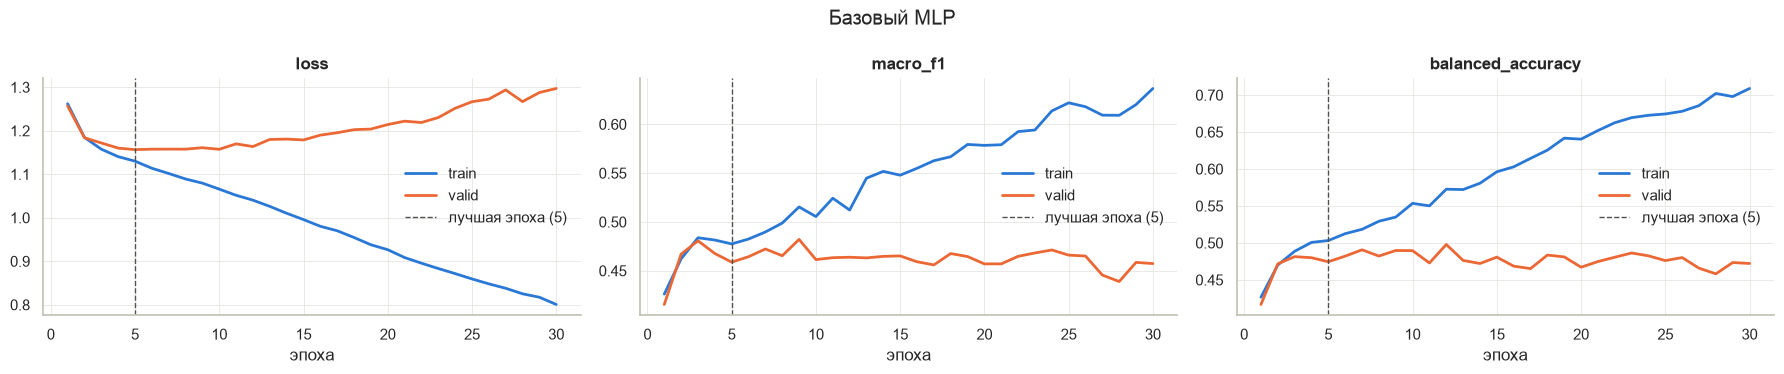

In [19]:
plots.plot_history(h, metrics=("loss", "macro_f1", "balanced_accuracy"), title="Базовый MLP");

In [20]:
baseline_scores = pd.DataFrame({split: baseline.evaluate(*data[split]) for split in ("train", "valid")}).T
baseline_scores

,loss,macro_f1,accuracy,balanced_accuracy
train,1.1300,0.4775,0.5655,0.5032
valid,1.1565,0.4588,0.5623,0.4745


               precision    recall  f1-score   support

no_disability      0.671     0.658     0.664       459
      adl_ge4      0.255     0.478     0.332       138
       severe      0.196     0.198     0.197        91
   died_lt2mo      0.744     0.564     0.642       468

     accuracy                          0.562      1156
    macro avg      0.466     0.475     0.459      1156
 weighted avg      0.613     0.562     0.579      1156



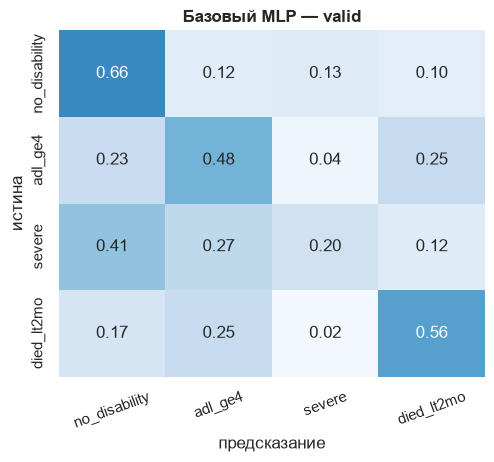

In [21]:
y_valid_pred = baseline.predict(data["valid"][0]).argmax(axis=1)
print(classification_report(data["valid"][1], y_valid_pred, target_names=support2.CLASS_NAMES, digits=3))
plots.plot_confusion_matrix(data["valid"][1], y_valid_pred, support2.CLASS_NAMES, title="Базовый MLP — valid");

**Вывод.**
* Early stopping сработал. Valid loss достигает минимума на 5-й эпохе и держится на плато примерно до 10-й, затем растёт, а train loss продолжает падать. Обучение остановлено на 30-й эпохе (25 эпох без улучшения), восстановлены веса 5-й эпохи.
* На лучшей эпохе разрыв train − valid небольшой (macro-F1 0.478 против 0.459, разница ≈ 0.02), то есть **у базовой модели переобучения нет**.
* На valid: macro-F1 = 0.459, accuracy = 0.562, balanced accuracy = 0.475 (случайное угадывание даёт ≈ 0.25).
* Крайние классы распознаются прилично: `no_disability` F1 = 0.66, `died_lt2mo` F1 = 0.64. Промежуточные хуже: `adl_ge4` F1 = 0.33, `severe` F1 = 0.20. По матрице ошибок `severe` в 41% случаев принимается за `no_disability` и в 27% за `adl_ge4`, а `adl_ge4` путается с обоими крайними классами (по ≈ 25%). Это согласуется с EDA: по признакам 3-го дня промежуточные классы сильно перекрываются с соседями.

### 4.1 Проверка на переобучение
1. **базовая модель** (сверху) — небольшая сеть, early stopping;
2. **большая сеть без регуляризации** — `[512, 512, 512]`, без dropout и weight decay, без early stopping, 200 эпох;
3. **та же большая сеть с регуляризацией** — dropout 0.7 и weight decay 0.5, тоже без early stopping.

In [22]:
overfit_cfg = replace(model_cfg, hidden_dims=OVERFIT_HIDDEN, dropout=0.0)
overfit_train = replace(TRAIN, weight_decay=0.0, patience=None, max_epochs=OVERFIT_EPOCHS)
overfit = train_model(overfit_cfg, overfit_train, data)

regularized_cfg = replace(overfit_cfg, dropout=REGULARIZED["dropout"])
regularized_train = replace(overfit_train, weight_decay=REGULARIZED["weight_decay"])
regularized = train_model(regularized_cfg, regularized_train, data)
print(f"параметров в большой сети: {count_parameters(overfit.model):,}")

параметров в большой сети: 557,060


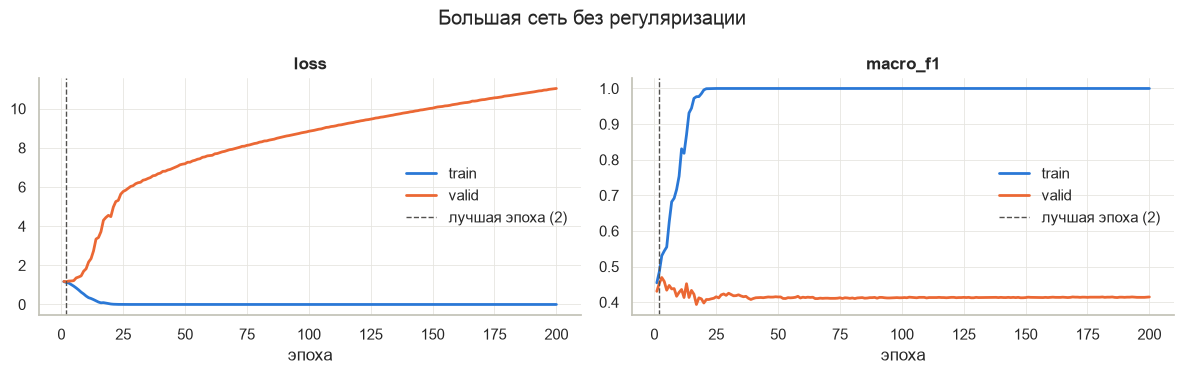

In [23]:
plots.plot_history(overfit.history, metrics=("loss", "macro_f1"), title="Большая сеть без регуляризации");

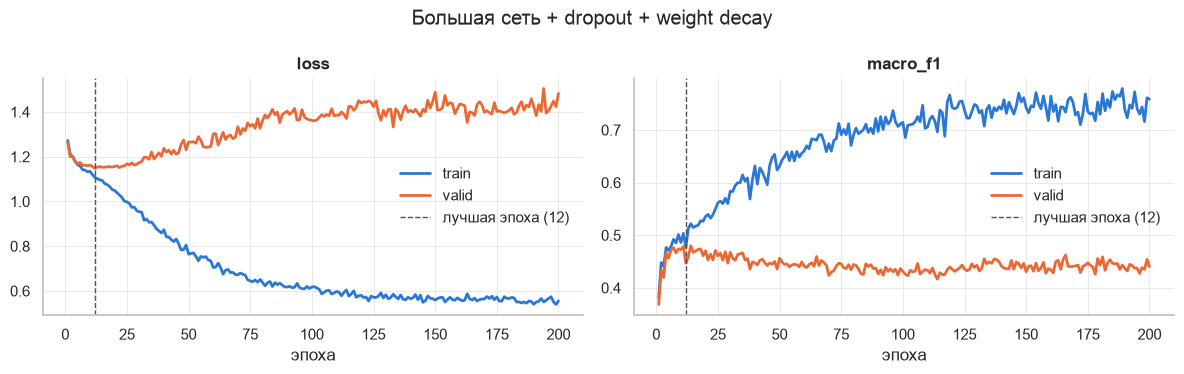

In [24]:
plots.plot_history(regularized.history, metrics=("loss", "macro_f1"), title="Большая сеть + dropout + weight decay");

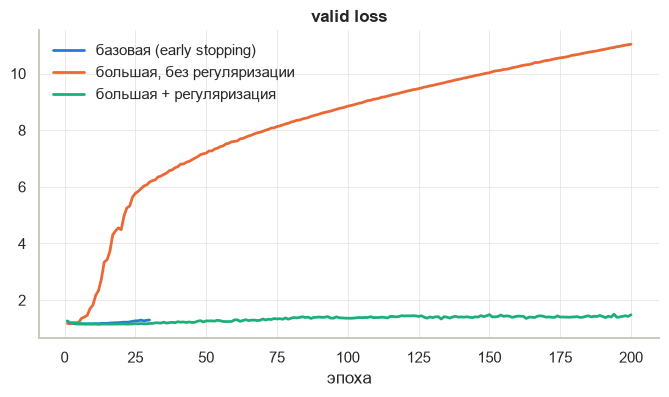

In [25]:
runs = {"базовая (early stopping)": baseline, "большая, без регуляризации": overfit, "большая + регуляризация": regularized}
plots.plot_histories({k: v.history for k, v in runs.items()}, metric="loss", split="valid", title="valid loss");

In [26]:
rows = []
for name, trainer in runs.items():
    tr, va = trainer.evaluate(*data["train"]), trainer.evaluate(*data["valid"])
    rows.append({"модель": name, "эпох": trainer.history.n_epochs, "лучшая эпоха": trainer.history.best_epoch + 1,
                 "train loss": tr["loss"], "valid loss": va["loss"],
                 "train macro-F1": tr["macro_f1"], "valid macro-F1": va["macro_f1"],
                 "разрыв F1 (train − valid)": tr["macro_f1"] - va["macro_f1"]})
overfit_table = pd.DataFrame(rows).set_index("модель")
overfit_table

,эпох,лучшая эпоха,train loss,valid loss,train macro-F1,valid macro-F1,разрыв F1 (train − valid)
модель,,,,,,,
базовая (early stopping),30,5,1.1300,1.1565,0.4775,0.4588,0.0187
"большая, без регуляризации",200,2,0.0000,11.0326,1.0000,0.4146,0.5854
большая + регуляризация,200,12,0.5554,1.4826,0.7586,0.4404,0.3182


**Вывод.**
* **Большая сеть без регуляризации** (557k параметров на 5.4k объектов) показывает классическое переобучение. Train loss уходит в 0, а train macro-F1 = 1.0 примерно к 20-й эпохе: сеть **запомнила** обучающую выборку. Valid loss при этом растёт с ≈ 1.16 до 11.0, valid macro-F1 падает до 0.415. Разрыв F1 = 0.585. Минимум valid loss — на 2-й эпохе, дальше модель только ухудшается.
* **Dropout 0.7 + weight decay 0.5** сильно сокращают разрыв: train macro-F1 = 0.76 вместо 1.0, valid loss = 1.48 вместо 11.0, разрыв = 0.32 вместо 0.585. Но при обучении 200 эпох без остановки переобучение полностью не устраняется.
* **Базовая модель с early stopping** не переобучена (разрыв 0.019), а по valid она лучше обеих больших сетей (0.459 против 0.415 и 0.440). На шумных табличных данных главная защита — **ранняя остановка по valid и умеренный размер модели**. Dropout и weight decay дополняют её, но не заменяют.

## 5. Влияние глубины и ширины MLP

Сетка: глубина (число скрытых слоёв) ∈ {1, 2, 3, 4, 6, 8} × ширина (нейронов в слое) ∈ {16, 32, 64, 128, 256, 512},
по 3 сида на каждую точку — всего 108 обучений. Всё остальное как у базовой модели (dropout 0.2, AdamW, early stopping),
поэтому разница объясняется только архитектурой. Метрики берутся на лучшей по valid loss эпохе и усредняются по сидам.

Результаты кэшируются в `results/depth_width_grid.csv`; чтобы пересчитать, поставьте `RERUN_GRID = True`.

In [27]:
grid = run_depth_width_grid(model_cfg, TRAIN, data, depths=GRID_DEPTHS, widths=GRID_WIDTHS, seeds=GRID_SEEDS,
                            cache_path=GRID_CACHE, rerun=RERUN_GRID)
grid["f1_gap"] = grid["train_macro_f1"] - grid["valid_macro_f1"]
summary = summarize_grid(grid, ["valid_macro_f1", "valid_loss", "train_macro_f1", "f1_gap", "best_epoch"])
print("запусков:", len(grid), "| суммарное время обучения:", f"{grid['fit_time_sec'].sum() / 60:.1f} мин")
summary.sort_values("valid_macro_f1_mean", ascending=False).head(10)

запусков: 108 | суммарное время обучения: 2.8 мин


,depth,width,valid_macro_f1_mean,valid_macro_f1_std,valid_loss_mean,valid_loss_std,train_macro_f1_mean,train_macro_f1_std,f1_gap_mean,f1_gap_std,best_epoch_mean,best_epoch_std,n_params
2,1,64,0.4747,0.0028,1.1486,0.0079,0.4874,0.0076,0.0127,0.0092,9.0000,1.0000,3972.0000
15,3,128,0.4730,0.0079,1.1494,0.0037,0.5089,0.0114,0.0359,0.0051,5.6667,1.5275,40964.0000
9,2,128,0.4715,0.0107,1.1504,0.0043,0.4971,0.0063,0.0257,0.0113,5.3333,1.1547,24452.0000
14,3,64,0.4704,0.0069,1.1474,0.0019,0.4950,0.0071,0.0246,0.0092,9.3333,1.1547,12292.0000
8,2,64,0.4701,0.0134,1.1522,0.0038,0.4989,0.0047,0.0288,0.0181,10.0000,1.0000,8132.0000
5,1,512,0.4683,0.0047,1.1496,0.0026,0.5045,0.0187,0.0362,0.0233,4.0000,2.6458,31748.0000
10,2,256,0.4678,0.0130,1.1493,0.0037,0.4948,0.0054,0.0270,0.0155,3.0000,1.0000,81668.0000
4,1,256,0.4674,0.0117,1.1496,0.0056,0.5060,0.0072,0.0386,0.0072,6.6667,1.5275,15876.0000
0,1,16,0.4672,0.0028,1.1496,0.0026,0.4849,0.0063,0.0178,0.0051,27.0000,4.3589,996.0000
3,1,128,0.4669,0.0120,1.1468,0.0024,0.4922,0.0122,0.0253,0.0031,8.6667,1.5275,7940.0000


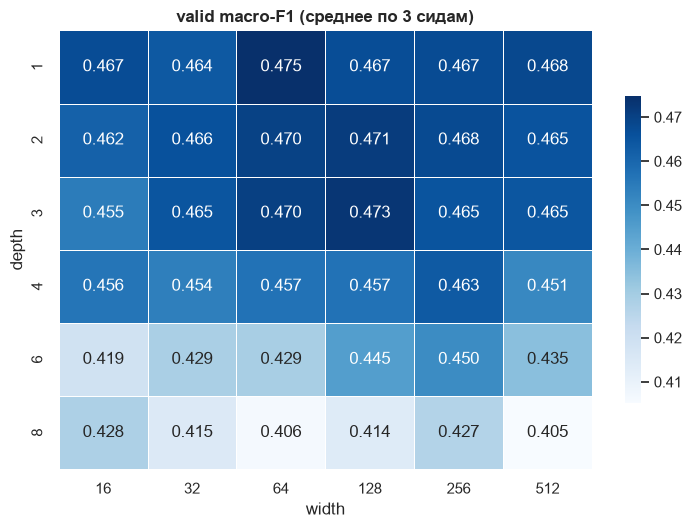

In [28]:
plots.plot_grid_heatmap(summary, "valid_macro_f1_mean", title="valid macro-F1 (среднее по 3 сидам)");

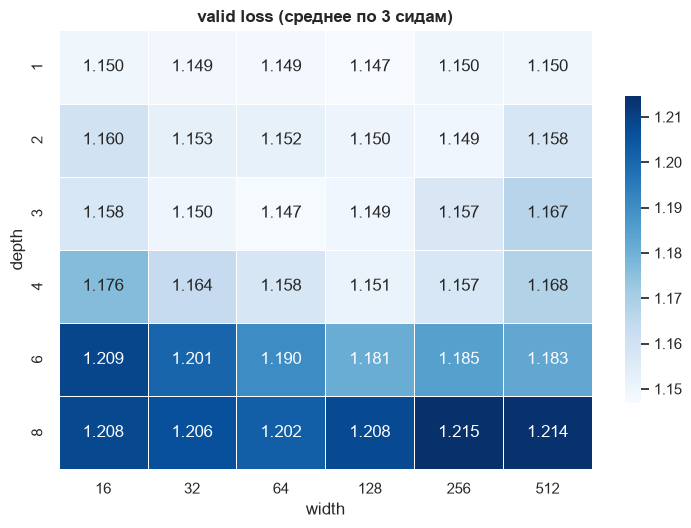

In [29]:
plots.plot_grid_heatmap(summary, "valid_loss_mean", title="valid loss (среднее по 3 сидам)");

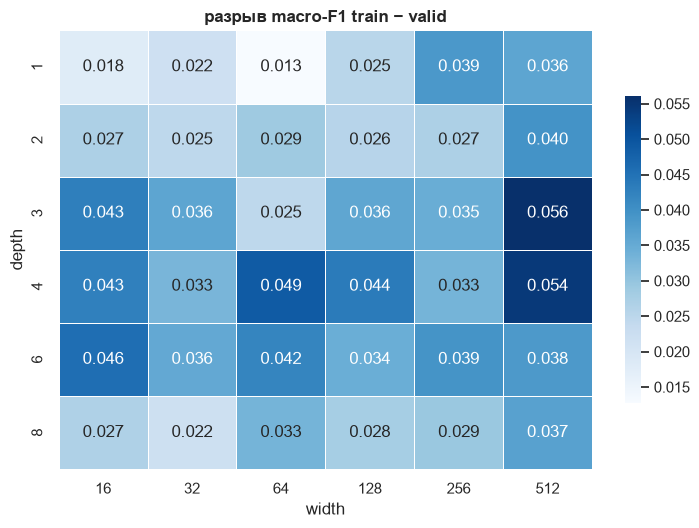

In [30]:
plots.plot_grid_heatmap(summary, "f1_gap_mean", title="разрыв macro-F1 train − valid");

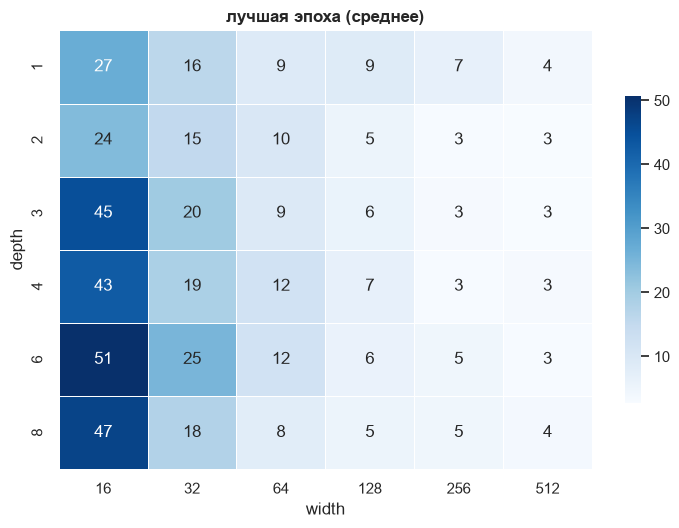

In [31]:
plots.plot_grid_heatmap(summary, "best_epoch_mean", title="лучшая эпоха (среднее)", fmt=".0f");

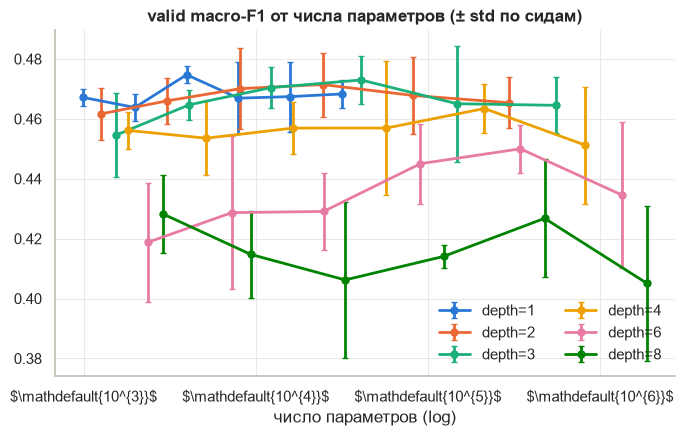

In [32]:
plots.plot_metric_vs_params(grid, "valid_macro_f1", hue="depth", title="valid macro-F1 от числа параметров (± std по сидам)");

In [33]:
pd.DataFrame({
    "по глубине": summary.groupby("depth")["valid_macro_f1_mean"].mean(),
}).T.round(4)

depth,1,2,3,4,6,8
по глубине,0.4681,0.4671,0.4654,0.4564,0.4343,0.4159


In [34]:
pd.DataFrame({
    "по ширине": summary.groupby("width")["valid_macro_f1_mean"].mean(),
}).T.round(4)

width,16,32,64,128,256,512
по ширине,0.4477,0.4486,0.4512,0.4546,0.4568,0.4482


### 5.1 Сравнение с базовой моделью и итоговая оценка на test

Лучшую конфигурацию сетки выбираем **по valid**, переобучаем с тем же сидом, что и базовую, и только после этого
**один раз** оцениваем обе модели на test.

In [35]:
best = summary.loc[summary["valid_macro_f1_mean"].idxmax()]
best_hidden = [int(best["width"])] * int(best["depth"])
print(f"лучшая по valid: depth={int(best['depth'])}, width={int(best['width'])}, "
      f"valid macro-F1 = {best['valid_macro_f1_mean']:.4f} ± {best['valid_macro_f1_std']:.4f}")

best_model = train_model(replace(model_cfg, hidden_dims=best_hidden), TRAIN, data)
torch.save(best_model.model.state_dict(), RESULTS_DIR / "best_grid.pt")

final = pd.DataFrame({
    f"базовая {BASELINE_HIDDEN}": {**{f"valid {k}": v for k, v in baseline.evaluate(*data["valid"]).items()},
                                   **{f"test {k}": v for k, v in baseline.evaluate(*data["test"]).items()},
                                   "параметров": count_parameters(baseline.model)},
    f"лучшая из сетки {best_hidden}": {**{f"valid {k}": v for k, v in best_model.evaluate(*data["valid"]).items()},
                                       **{f"test {k}": v for k, v in best_model.evaluate(*data["test"]).items()},
                                       "параметров": count_parameters(best_model.model)},
})
final

лучшая по valid: depth=1, width=64, valid macro-F1 = 0.4747 ± 0.0028


,"базовая [128, 64]",лучшая из сетки [64]
valid loss,1.1565,1.1554
valid macro_f1,0.4588,0.4786
valid accuracy,0.5623,0.5718
valid balanced_accuracy,0.4745,0.4961
test loss,1.1519,1.1392
test macro_f1,0.4522,0.4762
test accuracy,0.5536,0.5735
test balanced_accuracy,0.4787,0.4947
параметров,15940.0000,3972.0000


               precision    recall  f1-score   support

no_disability      0.703     0.686     0.695       459
      adl_ge4      0.301     0.453     0.362       137
       severe      0.151     0.286     0.198        91
   died_lt2mo      0.788     0.554     0.651       469

     accuracy                          0.574      1156
    macro avg      0.486     0.495     0.476      1156
 weighted avg      0.646     0.574     0.598      1156



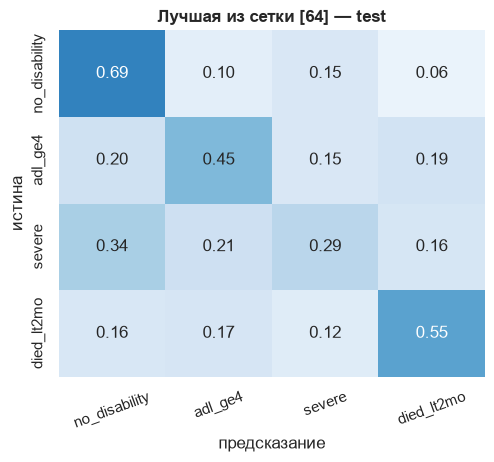

In [36]:
y_test_pred = best_model.predict(data["test"][0]).argmax(axis=1)
print(classification_report(data["test"][1], y_test_pred, target_names=support2.CLASS_NAMES, digits=3))
plots.plot_confusion_matrix(data["test"][1], y_test_pred, support2.CLASS_NAMES, title=f"Лучшая из сетки {best_hidden} — test");

**Вывод.**
* **Глубина вредит, начиная с 4 слоёв.** Средний valid macro-F1 по глубине: 0.468 (1 слой), 0.467 (2), 0.465 (3), 0.456 (4), 0.434 (6), 0.416 (8). Между 1, 2 и 3 слоями разница ≈ 0.003, это шум. С 6–8 слоями качество падает на 0.03–0.05, а разброс между сидами растёт (std до 0.026 против ≈ 0.003–0.012 у мелких сетей). Глубокие сети труднее оптимизировать, градиент проходит через длинную цепочку слоёв (см. п.6).
* **Ширина влияет слабо.** Средние по ширинам лежат в диапазоне 0.448–0.457, это сравнимо с разбросом между сидами. Ширина сильнее меняет **скорость** переобучения, чем итоговое качество: лучшая эпоха ≈ 24–50 при ширине 16 и ≈ 3–4 при ширине 512. При ширине 512 больше и разрыв train − valid (≈ 0.044 против ≈ 0.03).
* **Лучшая точка сетки** — 1 скрытый слой из 64 нейронов (≈ 4k параметров), valid macro-F1 = 0.475 ± 0.003. При этом десять лучших конфигураций лежат в пределах 0.008, примерно одного std между сидами. Статистически они неразличимы.
* **Сравнение с базовой.** Переобученная с тем же сидом `[64]` получила valid 0.479 и **test 0.476**, базовая `[128, 64]` — valid 0.459 и **test 0.452**. На этом разбиении маленькая модель лучше на ≈ 0.02 при вчетверо меньшем числе параметров. Но разница того же порядка, что разброс между сидами (std до 0.013), поэтому говорить о надёжном превосходстве нельзя. Вывод такой: увеличение ёмкости MLP не помогает, ограничивает информативность признаков 3-го дня. Из равных по качеству моделей разумно брать **более простую**.

## 6. Извлечение градиентов по слоям при инференсе объекта

`GradientExtractor` (`mlp_lab/gradients.py`) работает с любой `nn.Module`. При входе в `with` он вешает forward-hooks
на все слои заданного типа (по умолчанию `nn.Linear`), при выходе гарантированно их снимает. Для одного объекта:

1. forward в режиме `eval` (dropout выключен); hook сохраняет выход слоя и регистрирует на нём `tensor.register_hook`;
2. loss по истинной метке → `backward()`;
3. для каждого слоя собираются **dL/dW** и **dL/db** (`param.grad`), **dL/d(выход слоя)** (то, что пришло в слой сверху) и
   **dL/dx** — градиент по входным признакам (saliency: какие признаки сильнее всего двигают loss).

Если не передать `target`, градиент считается от логита предсказанного класса: «что заставило модель выбрать этот класс».

Возьмём два объекта из test: один базовая модель классифицирует верно, другой — с ошибкой.

In [37]:
X_test, y_test = data["test"]
test_pred = baseline.predict(X_test).argmax(axis=1)
rng = np.random.default_rng(SEED)
idx_correct = int(rng.choice(np.flatnonzero(test_pred == y_test)))
idx_wrong = int(rng.choice(np.flatnonzero(test_pred != y_test)))
objects = {"верно": idx_correct, "ошибка": idx_wrong}
for name, i in objects.items():
    print(f"{name:7s} idx={i:4d}  истина={support2.CLASS_NAMES[y_test[i]]:14s} предсказание={support2.CLASS_NAMES[test_pred[i]]}")

верно   idx=  84  истина=no_disability  предсказание=no_disability
ошибка  idx= 898  истина=no_disability  предсказание=adl_ge4


In [38]:
def extract(model, i, target=True):
    x = torch.tensor(X_test[i : i + 1])
    t = torch.tensor(y_test[i : i + 1]) if target else None
    with GradientExtractor(model) as extractor:
        return extractor.extract(x, t)

reports = {name: extract(baseline.model, i) for name, i in objects.items()}
for name, report in reports.items():
    probs = torch.softmax(torch.tensor(report.outputs), dim=1).numpy().round(3)
    print(f"{name:7s} loss={report.loss:.4f}  вероятности={dict(zip(support2.CLASS_NAMES, probs[0]))}")

верно   loss=0.5455  вероятности={'no_disability': np.float32(0.58), 'adl_ge4': np.float32(0.109), 'severe': np.float32(0.287), 'died_lt2mo': np.float32(0.025)}
ошибка  loss=1.3369  вероятности={'no_disability': np.float32(0.263), 'adl_ge4': np.float32(0.338), 'severe': np.float32(0.254), 'died_lt2mo': np.float32(0.145)}


In [39]:
layer = reports["верно"].layers["net.0"]
print("слой net.0:", "W.grad", layer.weight_grad.shape, "| b.grad", layer.bias_grad.shape,
      "| выход", layer.output.shape, "| dL/d(выход)", layer.output_grad.shape)
print("dL/dx:", reports["верно"].input_grad.shape)
pd.concat({name: r.norms() for name, r in reports.items()}, axis=1)

слой net.0: W.grad (128, 57) | b.grad (128,) | выход (1, 128) | dL/d(выход) (1, 128)
dL/dx: (1, 57)


верно                                              \
      weight_grad_norm bias_grad_norm output_grad_norm output_norm   
layer                                                                
net.0           1.1507         0.2378           0.2378      5.3988   
net.3           1.2307         0.2820           0.2820      4.9172   
net.6           2.2255         0.5210           0.5210      2.3567   

                ошибка                                              
      weight_grad_norm bias_grad_norm output_grad_norm output_norm  
layer                                                               
net.0           3.9778         0.7190           0.7190      5.0673  
net.3           2.2416         0.6075           0.6075      2.5939  
net.6           2.0161         0.8623           0.8623      0.6345

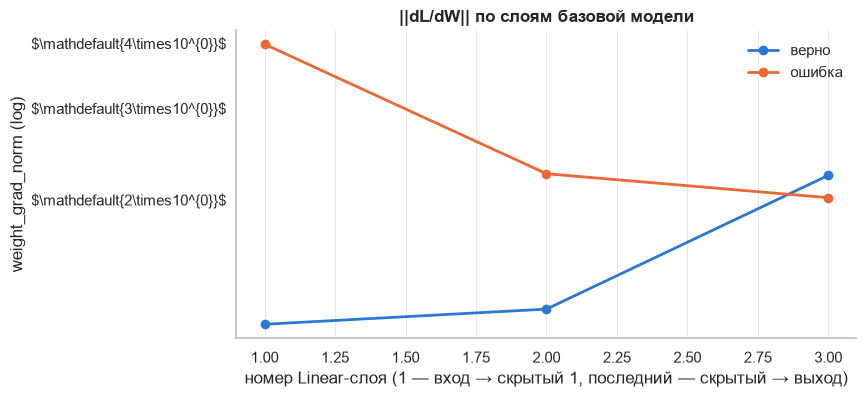

In [40]:
plots.plot_gradient_norms({name: r.norms() for name, r in reports.items()}, "weight_grad_norm",
                          title="||dL/dW|| по слоям базовой модели");

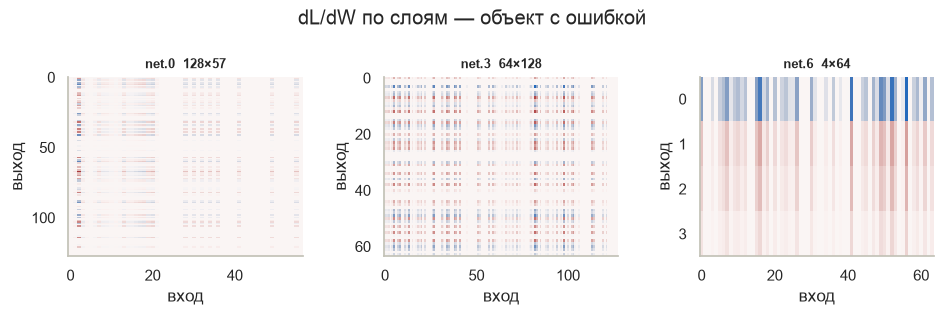

In [41]:
plots.plot_weight_gradient_heatmaps(reports["ошибка"], title="dL/dW по слоям — объект с ошибкой");

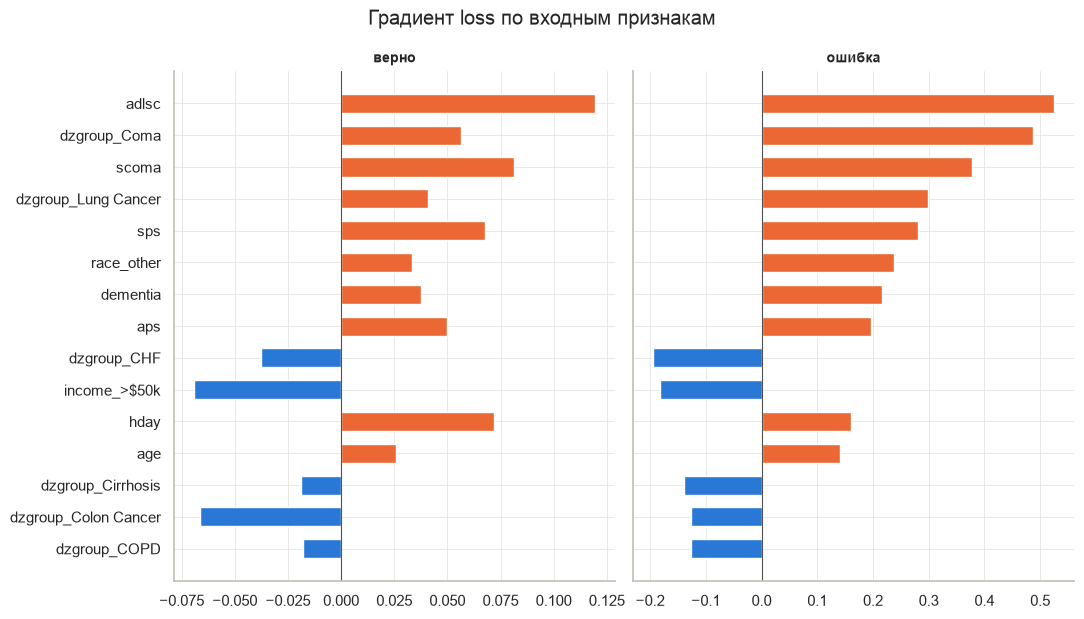

In [42]:
plots.plot_input_gradients({name: r.input_grad for name, r in reports.items()}, feature_names, top_k=15);

**Вывод.**
* Оба объекта на самом деле `no_disability`. **Верный** объект модель классифицирует с умеренной уверенностью (p = 0.58, loss = 0.55). **Ошибочный** отнесён к `adl_ge4`: вероятности размыты, а истинный класс получил всего 0.26 (loss = 1.34). У ошибочного объекта dL/d(выход) больше во всех слоях в 1.65–3 раза, а dL/dW первого слоя — в 3.5 раза: чем сильнее ошибка, тем больше сигнал для обновления весов. В последнем слое dL/dW у двух объектов сопоставима, потому что dL/dW = (dL/dz)ᵀ · h, а активации предыдущего слоя у ошибочного объекта вдвое меньше по норме (2.6 против 4.9).
* `||dL/db||` = `||dL/d(выход)||` в каждом слое: производная выхода Linear по bias равна 1. Это удобная проверка корректности.
* Heatmap dL/dW состоит из «полос»: для одного объекта dL/dW = (dL/dz)ᵀ · x — **внешнее произведение, матрица ранга 1**. Нулевые строки — нейроны, у которых ReLU в нуле и производная 0. Нулевые столбцы — нулевые входы. В последнем слое строка истинного класса `no_disability` отрицательная, остальные положительные. Для softmax + cross-entropy dL/dz_k = p_k − y_k, поэтому шаг градиентного спуска поднимет логит истинного класса и опустит остальные, сильнее всего — у ошибочно выбранного `adl_ge4`.
* Градиент по входу (saliency) клинически осмыслен. Положительный градиент (рост признака увеличивает loss, то есть уводит от «нет инвалидизации») у `adlsc`, `dzgroup_Coma`, `scoma`, `sps`, `aps`, `dementia`, `age`, `hday`: это шкалы тяжести и исходной беспомощности. Отрицательный (тянет к `no_disability`) у `dzgroup_CHF`, `dzgroup_Colon Cancer`, `income_>$50k`. Ровно эти группы в EDA имели наибольшую долю пациентов без инвалидизации.

### 6.1 Базовая сеть против глубокой (8 слоёв)

Обучим сеть `[64] × 8` с теми же настройками и сравним, как норма градиента меняется от выходного слоя к входному.
Если градиент при обратном распространении по слоям заметно затухает, первые слои учатся медленнее.

глубокая сеть: лучшая эпоха 15, valid macro-F1 = 0.4512


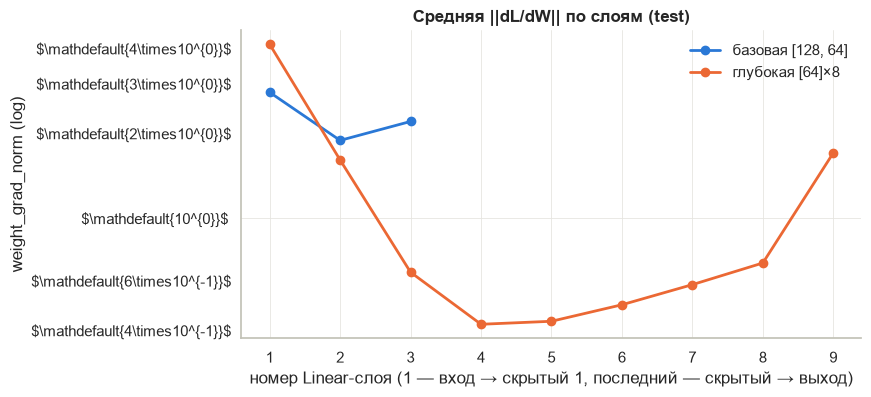

In [43]:
deep = train_model(replace(model_cfg, hidden_dims=DEEP_HIDDEN), TRAIN, data)
print(f"глубокая сеть: лучшая эпоха {deep.history.best_epoch + 1}, valid macro-F1 = {deep.evaluate(*data['valid'])['macro_f1']:.4f}")

# Нормы усредняем по всем объектам test, чтобы сравнение не зависело от одного случайного объекта.
def mean_norms(model):
    frames = [extract(model, i).norms() for i in range(len(X_test))]
    return sum(frames) / len(frames)

norms_cmp = {"базовая [128, 64]": mean_norms(baseline.model), "глубокая [64]×8": mean_norms(deep.model)}
plots.plot_gradient_norms(norms_cmp, "weight_grad_norm", title="Средняя ||dL/dW|| по слоям (test)");

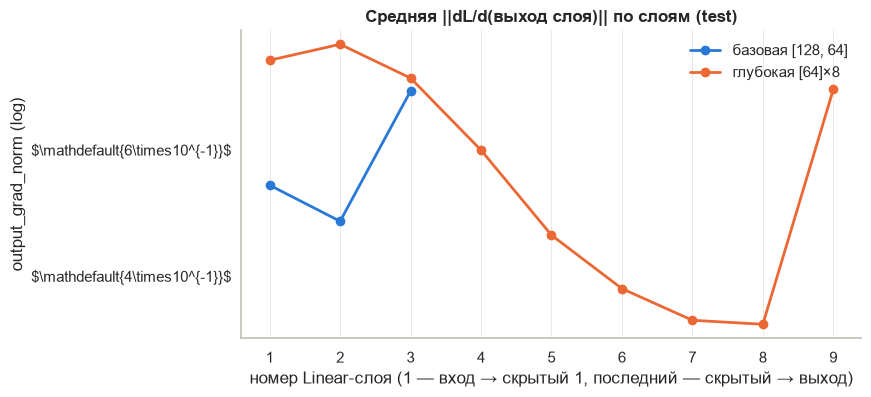

In [44]:
plots.plot_gradient_norms(norms_cmp, "output_grad_norm", title="Средняя ||dL/d(выход слоя)|| по слоям (test)");

In [45]:
pd.concat(norms_cmp, axis=0)[["weight_grad_norm", "output_grad_norm", "output_norm"]]

weight_grad_norm  output_grad_norm  output_norm
                  layer                                                  
базовая [128, 64] net.0             2.7941            0.5351       5.3319
                  net.3             1.8863            0.4766       3.5767
                  net.6             2.2020            0.7242       1.4534
глубокая [64]×8   net.0             4.1369            0.7994       3.9962
                  net.3             1.6076            0.8415       2.2755
                  net.6             0.6426            0.7549       2.0727
                  net.9             0.4200            0.5989       2.5770
                  net.12            0.4304            0.4558       3.2751
                  net.15            0.4926            0.3839       3.6786
                  net.18            0.5806            0.3468       3.7323
                  net.21            0.6929            0.3423       3.7862
                  net.24            1.7032            0.7278       1.4176

**Вывод.**
* **Затухания градиента нет.** `||dL/d(выход слоя)||` в 8-слойной сети от выхода к входу не убывает монотонно. Сначала она падает с 0.73 до ≈ 0.34 в слоях у выхода, затем снова растёт до ≈ 0.8 у входа. На протяжении всех 9 слоёв норма остаётся одного порядка (разница ≈ 2.5 раза). Это заслуга ReLU (производная 1 при x > 0, нет насыщения) и инициализации PyTorch по умолчанию (Kaiming-uniform), которая сохраняет масштаб сигнала. С sigmoid или tanh (f' ≤ 0.25 и ≤ 1) градиент затухал бы экспоненциально с глубиной.
* `||dL/dW||` меняется сильнее (≈ 0.42 в середине против 4.1 у входа), но это эффект не распространения градиента: dL/dW = (dL/dz)ᵀ · x зависит и от нормы входа слоя. Распространение градиента корректнее сравнивать по `||dL/d(выход)||`.
* С этим сидом глубокая сеть дала valid macro-F1 = 0.451, сопоставимо с базовой. Но в сетке та же архитектура `[64]×8` в среднем даёт 0.406 ± 0.026: глубокие сети нестабильны, их качество сильно зависит от инициализации. Причина проблем глубокого MLP на этих данных — не затухание градиента, а сложность оптимизации и склонность к переобучению. Помогают BatchNorm/LayerNorm, residual-связи и подбор lr.

## 7. Функции активации

Реализованы на NumPy в `mlp_lab/activations.py` вместе с производными и собраны в реестр:

```python
act = activations.get_activation("leaky_relu", alpha=0.1)
act(x), act.derivative(x)
```

Новая функция добавляется декоратором `@register("name", derivative=...)`, и её сразу видят `list_activations`,
`plot_activations` и `verify_against_torch`.

In [46]:
print("реализовано:", len(activations.list_activations()))
print(activations.list_activations())

реализовано: 18
['linear', 'step', 'sigmoid', 'tanh', 'relu', 'leaky_relu', 'prelu', 'elu', 'selu', 'gelu', 'silu', 'mish', 'softplus', 'softsign', 'hard_sigmoid', 'hard_tanh', 'relu6', 'softmax']


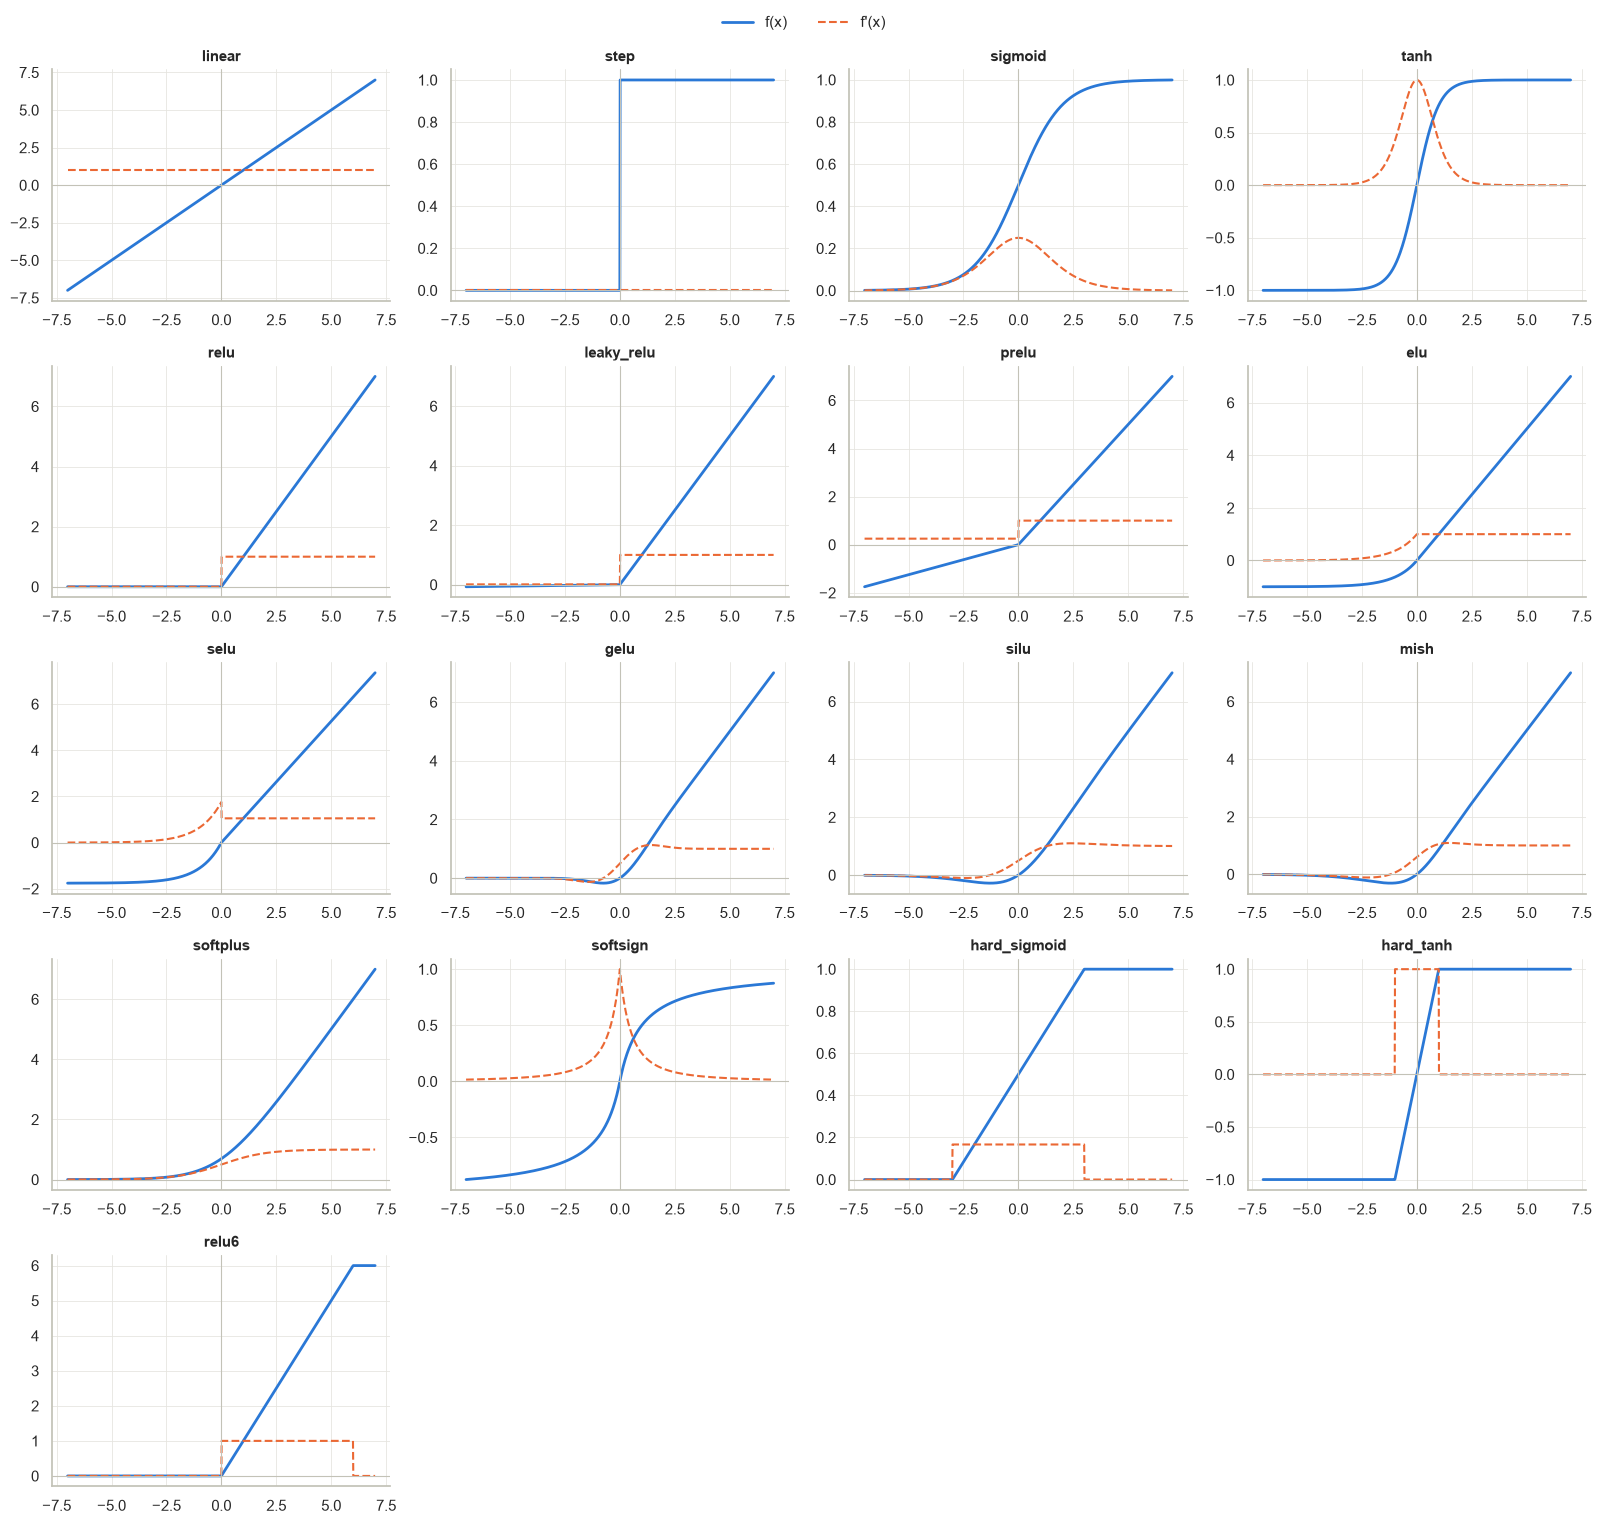

In [47]:
plots.plot_activations(activations.list_activations(elementwise=True), x_range=(-7, 7));

Softmax — не поэлементная функция: она превращает вектор логитов в распределение вероятностей.
Её производная — якобиан `diag(s) − s·sᵀ`. Температура `T` управляет «остротой» распределения.

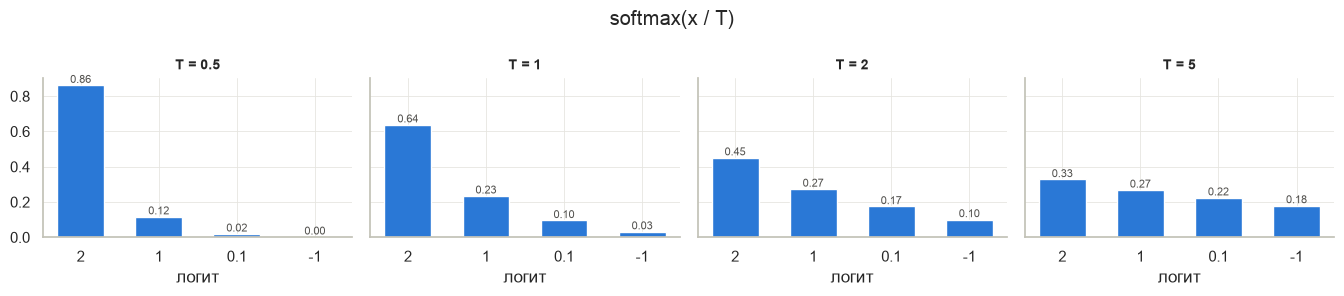

In [48]:
plots.plot_softmax([2.0, 1.0, 0.1, -1.0]);

In [49]:
x = np.array([[1.0, 2.0, 3.0]])
print("softmax:", activations.get_activation("softmax")(x).round(4))
print("якобиан:\n", activations.get_activation("softmax").derivative(x)[0].round(4))

softmax: [[0.09   0.2447 0.6652]]
якобиан:
 [[ 0.0819 -0.022  -0.0599]
 [-0.022   0.1848 -0.1628]
 [-0.0599 -0.1628  0.2227]]


**Сверка с PyTorch:** значения и производные (через autograd) на 10 000 случайных точек из U(−6, 6).

In [50]:
with pd.option_context("display.float_format", "{:.1e}".format):
    display(activations.verify_against_torch())

,value_max_abs_err,grad_max_abs_err,value_ok,grad_ok
activation,,,,
linear,0.0e+00,0.0e+00,True,True
step,0.0e+00,0.0e+00,True,True
sigmoid,2.2e-16,2.2e-16,True,True
tanh,1.1e-16,2.2e-16,True,True
relu,0.0e+00,0.0e+00,True,True
leaky_relu,0.0e+00,0.0e+00,True,True
prelu,0.0e+00,0.0e+00,True,True
elu,1.1e-16,1.1e-16,True,True
selu,2.2e-16,4.4e-16,True,True


## 8. Выводы

1. **Данные.** SUPPORT2 — неоднородный клинический датасет: 22 числовых, 2 бинарных и 5 категориальных признаков, до 53% пропусков, несбалансированные классы. Из него убрана **утечка таргета** (исходы, длительность и стоимость лечения, поздние решения, чужие прогнозы). Пропуски в анализах заполнены медицинскими нормами с флагами пропуска. Все статистики препроцессинга обучены только на train.
2. **Разбиение 70/15/15 со стратификацией:** train — веса, valid — early stopping и выбор архитектуры, test — однократная итоговая оценка.
3. **Базовый MLP** `[128, 64]` с dropout, весами классов и early stopping даёт macro-F1 = 0.459 на valid и 0.452 на test при случайном уровне 0.25. Крайние классы распознаются хорошо, промежуточные `adl_ge4`/`severe` хуже: по данным 3-го дня они почти неотличимы от соседей.
4. **Переобучение** продемонстрировано явно: большая сеть без регуляризации запоминает train (F1 = 1.0), а valid loss растёт с 1.16 до 11. Dropout и weight decay сокращают разрыв вдвое, early stopping устраняет его.
5. **Глубина и ширина:** 1–3 скрытых слоя дают одинаковое качество, с 6–8 слоями оно падает на 0.03–0.05 и растёт нестабильность между сидами. Ширина почти не влияет на качество, но ускоряет переобучение. Лучшая конфигурация `[64]` дала на test 0.476 против 0.452 у базовой. Разница в пределах разброса между сидами, но модель вчетверо меньше, и её стоит предпочесть.
6. **Градиенты:** реализовано извлечение dL/dW, dL/db, dL/d(выход) и dL/dx по каждому слою для любой модели. Ошибочные объекты дают большие градиенты. В 8-слойной ReLU-сети затухания градиента нет: норма dL/d(выход) остаётся одного порядка во всех слоях. Saliency подтверждает выводы EDA: важнее всего шкалы тяжести, кома, деменция и исходная бытовая активность.
7. **Функции активации:** 18 функций и их производные реализованы на NumPy, собраны в расширяемый реестр и совпадают с PyTorch с точностью < 1e-6.
8. **Воспроизводимость:** сид фиксируется до создания модели, вычисления идут на CPU, поэтому повторный запуск ноутбука даёт те же числа.